# 05 · CICIoT2023 (`IoT23`) — Phase 2 Data understanding
**Owner:** Yassine Mtibaa · **Project:** Cross-Network Intrusion Analysis (CRISP-DM) · **Phases in this notebook:** 2 (this version), 3 (added on Sunday)

Follows the structure required in `notebooks/README.md`:
1. Load the data and compare rows/columns with the official numbers (`docs/datasets.md`)
2. Columns, data types and units, grouped
3. Class distribution (table + figure in `figures/`)
4. Quality problems: NaN, infinite values, duplicates, constant columns, label spellings — plus logical checks specific to this dataset
5. Problem → planned solution table (no cleaning code yet)

**Data:** the `MERGED_CSV` release of CICIoT2023 (63 files `Merged01.csv … Merged63.csv`), placed in `data/raw/CICIoT2023/`.
**Size:** about 9.3 GB, so files are read **one by one in parallel** and only summaries are kept; every count below is computed on **all rows**. Plots use random samples.

In [1]:
import sys; sys.path.append("..")
from src.config import *

import time, pickle, multiprocessing as mp
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

SOURCE = "IoT23"
LABEL_COL = "Label"          # the MERGED_CSV release uses 'Label' (config.CICIOT_LABEL_COL says 'label', see decision log)
DATA = RAW_DIR / DATASETS[SOURCE]["file"]
all_csv = sorted(DATA.rglob("*.csv"))
# The CIC download contains the same data twice (MERGED_CSV/ and CSV/<attack>/): read only one copy.
merged = [p for p in all_csv if "merged" in p.name.lower() or "merged_csv" in str(p).lower()]
FILES = merged if merged else all_csv
CACHE = PROCESSED_DIR / "IoT23_phase2_profile.pkl"   # git-ignored cache of the full pass
print(f"{len(FILES)} files, {sum(f.stat().st_size for f in FILES)/1e9:.2f} GB in {DATA}")

63 files, 9.30 GB in /home/yassine/cross-network-intrusion-analysis/data/raw/CICIoT2023


## 2.1 Rows and columns — first look at one file

In [2]:
first = pd.read_csv(FILES[0])
print(first.shape)
first.info()
first.head()

(712311, 40)
<class 'pandas.DataFrame'>
RangeIndex: 712311 entries, 0 to 712310
Data columns (total 40 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Header_Length    712311 non-null  float64
 1   Protocol Type    712311 non-null  int64  
 2   Time_To_Live     712311 non-null  float64
 3   Rate             712311 non-null  float64
 4   fin_flag_number  712311 non-null  float64
 5   syn_flag_number  712311 non-null  float64
 6   rst_flag_number  712311 non-null  float64
 7   psh_flag_number  712311 non-null  float64
 8   ack_flag_number  712311 non-null  float64
 9   ece_flag_number  712311 non-null  float64
 10  cwr_flag_number  712311 non-null  float64
 11  ack_count        712311 non-null  int64  
 12  syn_count        712311 non-null  int64  
 13  fin_count        712311 non-null  int64  
 14  rst_count        712311 non-null  int64  
 15  HTTP             712311 non-null  float64
 16  HTTPS            712311 non-null  fl

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label
0,19.92,6,63.36,25893.962218,0.0,0.0,0.0,0.99,0.99,0.0,0.0,99,0,0,0,0.0,0.01,0.0,0.0,0.0,0.0,0.0,0.99,0.00,0.0,0.01,0.00,0.0,0.99,0.99,6421,60,481,64.21,42.100000,64.21,0.000039,100,1772.410000,DDOS-PSHACK_FLOOD
1,0.00,47,64.00,3703.841331,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0,0,0,0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.00,0.01,0.0,1.00,1.00,57320,98,578,573.20,48.000000,573.20,0.000271,100,2304.000000,MIRAI-GREIP_FLOOD
2,7.92,17,65.91,19673.095685,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0,0,0,0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.99,0.0,0.00,0.01,0.0,1.00,1.00,6010,60,70,60.10,1.000000,60.10,0.000057,100,1.000000,DOS-UDP_FLOOD
3,20.40,6,110.50,261.664826,0.1,0.0,0.3,0.20,0.40,0.0,0.0,4,0,1,3,0.0,0.50,0.0,0.0,0.0,0.0,0.0,0.70,0.20,0.0,0.10,0.00,0.0,0.90,0.90,2223,54,1500,222.30,451.596686,222.30,0.004766,10,203939.566667,DNS_SPOOFING
4,0.32,1,63.96,28944.199848,0.0,0.0,0.0,0.00,0.01,0.0,0.0,1,0,0,0,0.0,0.01,0.0,0.0,0.0,0.0,0.0,0.01,0.00,0.0,0.00,0.99,0.0,1.00,1.00,6006,60,66,60.06,0.600000,60.06,0.000035,100,0.360000,DDOS-ICMP_FLOOD


### Full pass over all files
`profile_file` reads one file and returns only small summaries: counts per label, NaN/inf/negative counts per column, min/max/sum per column, the result of each logical rule, per-class anomaly counts, row hashes (to find duplicates across files) and two random samples. Ten files are processed at the same time.

The **logical rules** test relations that must hold if the columns mean what we think they mean. A rule with **0 violations** proves that one column is computed from others (redundant); a rule with violations reveals inconsistent values.

In [3]:
SHARE = ["fin_flag_number", "syn_flag_number", "rst_flag_number", "psh_flag_number", "ack_flag_number", "ece_flag_number",
         "cwr_flag_number", "HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC", "TCP", "UDP", "DHCP", "ARP", "ICMP", "IGMP", "IPv", "LLC"]
COUNTS = ["ack_count", "syn_count", "fin_count", "rst_count"]
PAIRS = dict(zip(COUNTS, ["ack_flag_number", "syn_flag_number", "fin_flag_number", "rst_flag_number"]))
WHOLE = COUNTS + ["Protocol Type", "Tot sum", "Min", "Max", "Number"]

RULES = {
    "Min > Max":                                lambda d: d["Min"] > d["Max"],
    "AVG outside [Min, Max]":                   lambda d: (d["AVG"] < d["Min"] - 1e-6) | (d["AVG"] > d["Max"] + 1e-6),
    "Std < 0 or Variance < 0":                  lambda d: (d["Std"] < 0) | (d["Variance"] < 0),
    "Time_To_Live outside [0, 255]":            lambda d: (d["Time_To_Live"] < 0) | (d["Time_To_Live"] > 255),
    "Number outside [1, 100]":                  lambda d: (d["Number"] < 1) | (d["Number"] > 100),
    "a *_count > Number":                       lambda d: d[COUNTS].max(axis=1) > d["Number"],
    "a share column outside [0, 1]":            lambda d: ((d[SHARE] < 0) | (d[SHARE] > 1)).any(axis=1),
    "Header_Length > 60 (max TCP header)":      lambda d: d["Header_Length"] > 60,
    "IAT < 0":                                  lambda d: d["IAT"] < 0,
    "Tot size != AVG":                          lambda d: ~np.isclose(d["Tot size"], d["AVG"], rtol=0, atol=1e-6),
    "IPv != LLC":                               lambda d: ~np.isclose(d["IPv"], d["LLC"], rtol=0, atol=1e-9),
    "Variance != Std^2":                        lambda d: ~np.isclose(d["Variance"], d["Std"] ** 2, rtol=0.02, atol=0.02),
    "Tot sum != AVG x Number":                  lambda d: ~np.isclose(d["Tot sum"], d["AVG"] * d["Number"], rtol=0.01, atol=1),
    "x_count != x_flag_number x Number":        lambda d: np.column_stack([~np.isclose(d[c], d[f] * d["Number"], rtol=0, atol=1.01) for c, f in PAIRS.items()]).any(axis=1),
    "TCP share > 0.5 but Protocol Type != 6":   lambda d: (d["TCP"] > 0.5) & (d["Protocol Type"] != 6),
    "UDP share > 0.5 but Protocol Type != 17":  lambda d: (d["UDP"] > 0.5) & (d["Protocol Type"] != 17),
    "ICMP share > 0.5 but Protocol Type != 1":  lambda d: (d["ICMP"] > 0.5) & (d["Protocol Type"] != 1),
}
ANOMALIES = {   # counted per class, to understand WHERE each anomaly happens
    "Header_Length = 0":    lambda d: d["Header_Length"] == 0,
    "Time_To_Live = 0":     lambda d: d["Time_To_Live"] == 0,
    "Max > 1514 bytes":     lambda d: d["Max"] > 1514,
    "Rate = inf":           lambda d: np.isinf(d["Rate"]),
    "IAT > 1 hour":         lambda d: d["IAT"] > 3600,
    "Protocol Type = 0":    lambda d: d["Protocol Type"] == 0,
    "Number < 100":         lambda d: d["Number"] < 100,
    "Std = NaN":            lambda d: d["Std"].isna(),
}

def profile_file(args):
    path, seed = args
    raw = pd.read_csv(path, low_memory=False)
    d = raw.rename(columns={c: c.strip() for c in raw.columns})
    feats = [c for c in d.columns if c != LABEL_COL]
    num = d[feats].astype("float64")
    fin = num.replace([np.inf, -np.inf], np.nan)
    lab = d[LABEL_COL]
    r = {"file": path.name, "rows": len(d), "cols": tuple(d.columns), "dtypes": {c: str(t) for c, t in raw.dtypes.items()},
         "labels": lab.value_counts(dropna=False).to_dict(),
         "nan": d.isna().sum().to_dict(), "inf": np.isinf(num).sum().to_dict(), "neg": (fin < 0).sum().to_dict(),
         "min": fin.min().to_dict(), "max": fin.max().to_dict(), "sum": fin.sum().to_dict(), "sumsq": (fin ** 2).sum().to_dict(),
         "n": fin.count().to_dict(), "nonint": {c: int((fin[c] % 1 != 0).sum()) for c in WHOLE},
         "proto": fin["Protocol Type"].value_counts().to_dict(),
         "broken": [(path.name, int(i), int(k)) for i, k in d.isna().sum(axis=1).items() if k >= 5],
         "std_nan_number": d.loc[d["Std"].isna() & (d.isna().sum(axis=1) < 5), "Number"].value_counts().to_dict()}
    r["rules"] = {k: int(np.asarray(pd.Series(f(fin)).fillna(False), dtype=bool).sum()) for k, f in RULES.items()}
    r["anom"] = {k: pd.Series(np.asarray(f(d.assign(Rate=num["Rate"])), dtype=bool)).groupby(lab.values).sum().to_dict() for k, f in ANOMALIES.items()}
    r["h_feat"] = pd.util.hash_pandas_object(d[feats], index=False).values
    lh = pd.util.hash_pandas_object(lab.astype(str), index=False).values       # labels as 64-bit codes (saves memory)
    r["lab_arr"] = lh; r["lab_map"] = dict(zip(lh, lab.astype(str).values))
    rng = np.random.default_rng(seed); key = rng.random(len(d))
    r["uniform"] = d.iloc[np.argsort(key)[:12_000]]                                   # ~750k rows over 63 files
    r["by_class"] = d.assign(_k=key)[lambda x: x.groupby(LABEL_COL)["_k"].rank(method="first") <= 400].drop(columns="_k")
    return r

if CACHE.exists():
    P = pickle.load(open(CACHE, "rb"))
else:
    t0 = time.time()
    with mp.get_context("fork").Pool(10) as pool:
        res = pool.map(profile_file, [(f, RANDOM_STATE + i) for i, f in enumerate(FILES)])
    print(f"full pass: {time.time() - t0:.0f}s")
    tot = lambda key: pd.Series(sum((Counter(r[key]) for r in res), Counter()))
    H = pd.DataFrame({"h": np.concatenate([r["h_feat"] for r in res]), "lab": np.concatenate([r["lab_arr"] for r in res])})
    LMAP = {k: v for r in res for k, v in r["lab_map"].items()}
    n_lab = H.groupby("h")["lab"].nunique()
    P = {"files": len(res), "rows": sum(r["rows"] for r in res), "layouts": len({r["cols"] for r in res}),
         "rows_per_file": pd.Series({r["file"]: r["rows"] for r in res}),
         "dtype_variants": {c: sorted({r["dtypes"].get(c) for r in res}) for c in res[0]["dtypes"]},
         "labels": tot("labels"), "nan": tot("nan"), "inf": tot("inf"), "neg": tot("neg"), "nonint": tot("nonint"), "proto": tot("proto"),
         "min": pd.DataFrame([r["min"] for r in res]).min(), "max": pd.DataFrame([r["max"] for r in res]).max(),
         "mean": tot("sum") / tot("n"), "std": np.sqrt((tot("sumsq") / tot("n") - (tot("sum") / tot("n")) ** 2).clip(lower=0)),
         "rules": tot("rules"), "broken": [b for r in res for b in r["broken"]], "std_nan_number": tot("std_nan_number"),
         "anom": pd.DataFrame({k: sum((Counter(r["anom"][k]) for r in res), Counter()) for k in ANOMALIES}).fillna(0).astype(int),
         "dup_rows": int(H.duplicated().sum()),                      # same features AND same label
         "dup_features": int(H["h"].duplicated().sum()),             # same features, any label
         "conflict_vectors": int((n_lab > 1).sum()),
         "conflict_rows_by_label": H[H["h"].isin(n_lab[n_lab > 1].index)]["lab"].map(LMAP).value_counts(),
         "dup_rows_by_label": H[H.duplicated()]["lab"].map(LMAP).value_counts(),
         "uniform": pd.concat([r["uniform"] for r in res], ignore_index=True),
         "by_class": pd.concat([r["by_class"] for r in res], ignore_index=True)}
    del res, H
    pickle.dump(P, open(CACHE, "wb"))
R = P["rows"]
print(f"{R:,} rows | {P['files']} files | {P['layouts']} column layout(s)")

45,019,243 rows | 63 files | 1 column layout(s)


In [4]:
official = pd.DataFrame({
    "docs/datasets.md": ["~47 million", "45 features"],
    "UNB website (2023 release)": ["46,686,579", "46 features + label"],
    "Loaded (MERGED_CSV release)": [f"{R:,}", f"{first.shape[1] - 1} features + Label"],
}, index=["Rows", "Columns"])
official

,docs/datasets.md,UNB website (2023 release),Loaded (MERGED_CSV release)
Rows,~47 million,"46,686,579","45,019,243"
Columns,45 features,46 features + label,39 features + Label


**Interpretation.** The files we downloaded are a **newer release** than the one described on the UNB page and in `docs/datasets.md`: 63 merged files instead of 169, and **40 columns instead of 47**. Compared with the original release, `Duration` was renamed `Time_To_Live`, `IGMP` was added, and `flow_duration`, `Srate`, `Drate`, `urg_count`, `Magnitue`, `Radius`, `Covariance` and `Weight` were removed. The row count is also slightly lower. All numbers in this project therefore come from the loaded files, not from the documentation.

**Granularity — what one row is.** A row is **one window of up to 100 packets** (`Number` = packets in the window, median 100). Every feature is a summary over that window: an average, a share between 0 and 1, a count, or a size statistic. There is **no identifier column** (no IP, port, device or timestamp).

## 2.2 Columns, data types and units

In [5]:
groups = {
    "Identifiers": [],
    "Ports / protocol": ["Protocol Type", "Header_Length", "Time_To_Live"],
    "Protocol shares (0-1)": ["HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC", "TCP", "UDP", "DHCP", "ARP", "ICMP", "IGMP", "IPv", "LLC"],
    "Volume (bytes, packets)": ["Tot sum", "Min", "Max", "AVG", "Std", "Tot size", "Variance", "Number"],
    "Time (rate, IAT)": ["Rate", "IAT"],
    "TCP flags": SHARE[:7] + COUNTS,
    "Labels": [LABEL_COL],
}
UNITS = {"Protocol Type": "IANA code (1 ICMP, 2 IGMP, 6 TCP, 17 UDP, 47 GRE, 0 other)", "Header_Length": "bytes (window average)",
         "Time_To_Live": "hops (window average)", "Tot sum": "bytes", "Min": "bytes", "Max": "bytes", "AVG": "bytes", "Std": "bytes",
         "Tot size": "bytes", "Variance": "bytes²", "Number": "packets in window", "Rate": "packets / s", "IAT": "seconds",
         LABEL_COL: "34 classes (text)"}
rows = []
for g, cols in groups.items():
    for c in cols:
        rows.append({"group": g, "column": c, "dtype": str(first[c].dtype),
                     "unit": UNITS.get(c, "share of packets in window (0-1)" if c in SHARE else "packets with this flag (0-100)" if c in COUNTS else ""),
                     "min": P["min"].get(c), "max": P["max"].get(c), "mean": P["mean"].get(c)})
dtypes_table = pd.DataFrame(rows)
assert set(dtypes_table["column"]) == set(first.columns), "every column must appear in exactly one group"
dtypes_table.to_csv(TABLE_DIR / "IoT23_phase2_columns.csv", index=False)
dtypes_table.round(4)

,group,column,dtype,unit,min,max,mean
0,Ports / protocol,Protocol Type,int64,"IANA code (1 ICMP, 2 IGMP, 6 TCP, 17 UDP, 47 G...",0.0000,4.700000e+01,9.0913
1,Ports / protocol,Header_Length,float64,bytes (window average),0.0000,6.000000e+01,13.7371
2,Ports / protocol,Time_To_Live,float64,hops (window average),0.0000,2.550000e+02,66.5317
3,Protocol shares (0-1),HTTP,float64,share of packets in window (0-1),0.0000,1.000000e+00,0.0502
4,Protocol shares (0-1),HTTPS,float64,share of packets in window (0-1),0.0000,1.000000e+00,0.0588
5,Protocol shares (0-1),DNS,float64,share of packets in window (0-1),0.0000,1.000000e+00,0.0026
6,Protocol shares (0-1),Telnet,float64,share of packets in window (0-1),0.0000,6.000000e-01,0.0000
7,Protocol shares (0-1),SMTP,float64,share of packets in window (0-1),0.0000,9.000000e-01,0.0000
8,Protocol shares (0-1),SSH,float64,share of packets in window (0-1),0.0000,1.000000e+00,0.0002
9,Protocol shares (0-1),IRC,float64,share of packets in window (0-1),0.0000,9.000000e-01,0.0000


In [6]:
print("columns whose dtype differs between files:", {c: v for c, v in P["dtype_variants"].items() if len(v) > 1})
print("Protocol Type values (rows):", P["proto"].astype(int).to_dict())
print("Number of labels:", int(P["labels"].index.notna().sum()))

columns whose dtype differs between files: {'ack_count': ['float64', 'int64'], 'syn_count': ['float64', 'int64'], 'fin_count': ['float64', 'int64'], 'rst_count': ['float64', 'int64'], 'Tot sum': ['float64', 'int64'], 'Min': ['float64', 'int64'], 'Max': ['float64', 'int64'], 'Number': ['float64', 'int64']}
Protocol Type values (rows): {6.0: 26211331, 17.0: 9817966, 1.0: 7321515, 47.0: 1655082, 0.0: 13345, 2.0: 4}
Number of labels: 34


**Interpretation.**
* All 39 features are numeric; `Label` is text. There are **no identifier, port or timestamp columns** at all.
* `Protocol Type` is stored as an integer but is a **categorical code** (only 6 distinct values).
* The 7 `*_flag_number` columns and the 15 protocol columns are **shares between 0 and 1** (e.g. 0.99), not 0/1 booleans as their names suggest, because every row summarises a window of packets.
* Eight integer columns are read as `float64` in a few files: those files contain truncated lines with empty cells (see 2.4).

## 2.3 Class distribution

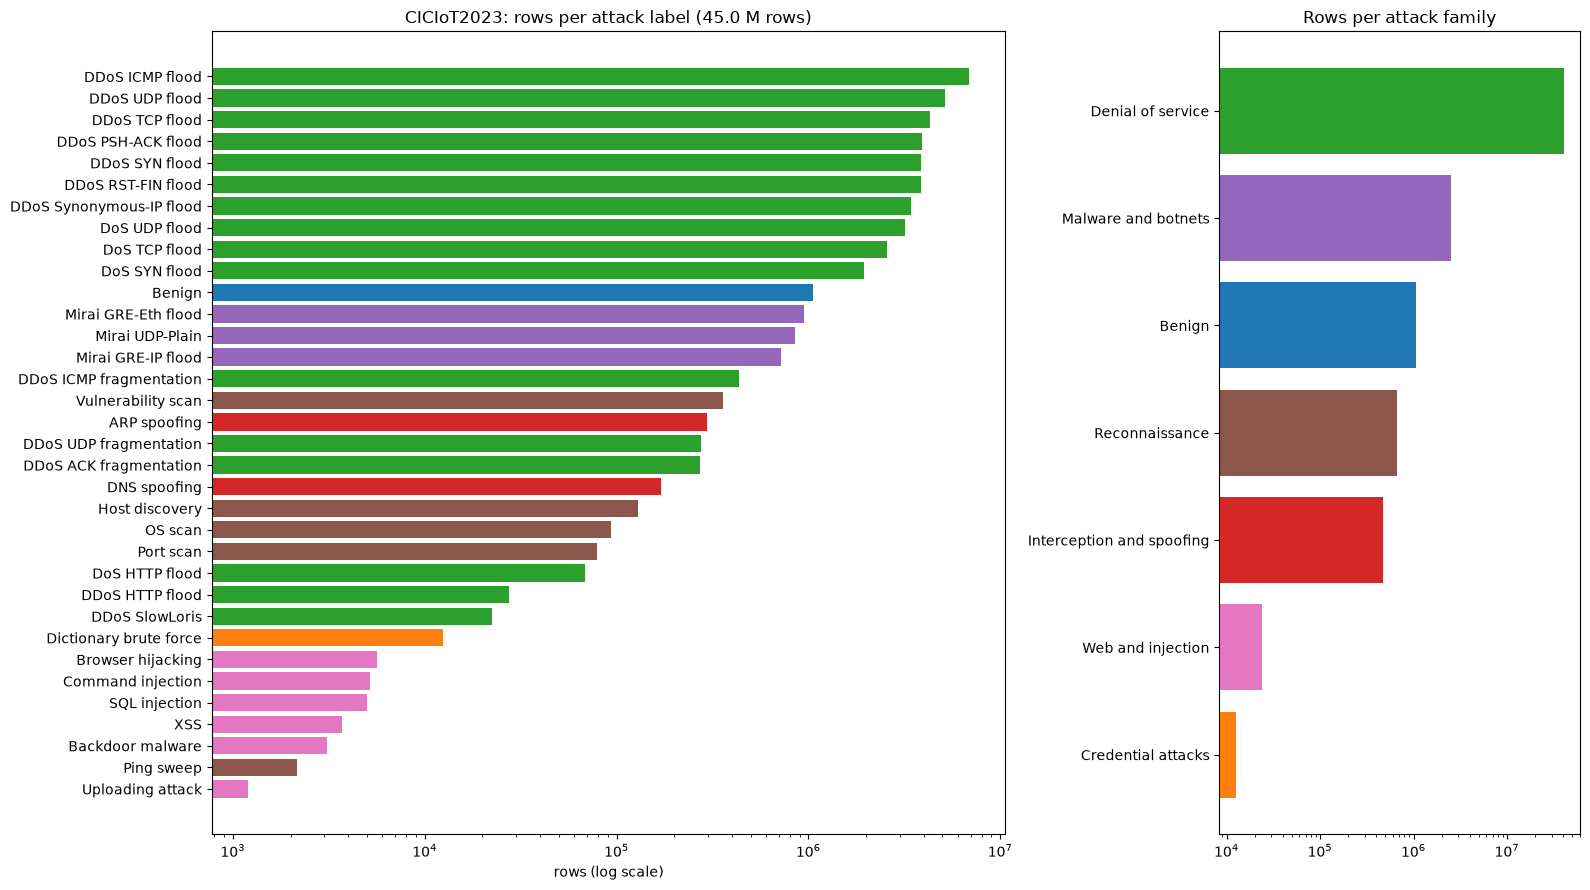

34 labels -> 7 families | largest/smallest = 5,764x | benign = 2.34 %


,original_label,attack_label,attack_family,rows,% of rows
0,DDOS-ICMP_FLOOD,DDoS ICMP flood,Denial of service,6893259,15.3118
1,DDOS-UDP_FLOOD,DDoS UDP flood,Denial of service,5181027,11.5085
2,DDOS-TCP_FLOOD,DDoS TCP flood,Denial of service,4306086,9.5650
3,DDOS-PSHACK_FLOOD,DDoS PSH-ACK flood,Denial of service,3920372,8.7082
4,DDOS-SYN_FLOOD,DDoS SYN flood,Denial of service,3886130,8.6322
5,DDOS-RSTFINFLOOD,DDoS RST-FIN flood,Denial of service,3872808,8.6026
6,DDOS-SYNONYMOUSIP_FLOOD,DDoS Synonymous-IP flood,Denial of service,3445659,7.6537
7,DOS-UDP_FLOOD,DoS UDP flood,Denial of service,3177323,7.0577
8,DOS-TCP_FLOOD,DoS TCP flood,Denial of service,2558256,5.6826
9,DOS-SYN_FLOOD,DoS SYN flood,Denial of service,1942176,4.3141


In [7]:
labels = P["labels"]; labels = labels[labels.index.notna()].sort_values(ascending=False).astype(int)
dist = map_labels(pd.DataFrame({LABEL_COL: labels.index}), LABEL_COL, SOURCE)      # stops with an error if a label is not in TAXONOMY
dist["rows"] = labels.values
dist["% of rows"] = (100 * dist["rows"] / R).round(4)
dist = dist.rename(columns={LABEL_COL: "original_label"})[["original_label", "attack_label", "attack_family", "rows", "% of rows"]]
dist.to_csv(TABLE_DIR / "IoT23_phase2_labels.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [2.2, 1]})
pal = dict(zip(sorted(dist["attack_family"].unique()), sns.color_palette("tab10")))
ax[0].barh(dist["attack_label"][::-1], dist["rows"][::-1], color=[pal[f] for f in dist["attack_family"][::-1]])
ax[0].set_xscale("log"); ax[0].set_xlabel("rows (log scale)"); ax[0].set_title(f"CICIoT2023: rows per attack label ({R/1e6:.1f} M rows)")
fam = dist.groupby("attack_family")["rows"].sum().sort_values()
ax[1].barh(fam.index, fam.values, color=[pal[f] for f in fam.index]); ax[1].set_xscale("log"); ax[1].set_title("Rows per attack family")
plt.tight_layout(); plt.savefig(FIG_DIR / "IoT23_class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"{len(dist)} labels -> {dist['attack_family'].nunique()} families | largest/smallest = {labels.iloc[0] / labels.iloc[-1]:,.0f}x "
      f"| benign = {dist.loc[dist.attack_family == BENIGN, '% of rows'].sum():.2f} %")
dist

**Interpretation.** All 34 original labels map to the shared taxonomy without changes (the UPPERCASE spellings are normalised by `map_labels`). The data is dominated by **Denial of service** (16 labels, ≈ 89 % of rows): `DDoS ICMP flood` alone is about 15 %. **Benign is only ≈ 2.3 %**, and the web attacks have a few thousand rows each (`Uploading attack`: 1,196). The largest label is about **5,800 times** the smallest: the sampling cap of 200k rows per label (`sample_per_label`) is essential here.

## 2.4 Quality problems
### Missing, infinite and negative values

In [8]:
q = pd.DataFrame({"NaN": P["nan"], "inf": P["inf"], "negative": P["neg"]}).fillna(0).astype(int)
q = q[(q != 0).any(axis=1)]
q["% of rows (max)"] = (100 * q.max(axis=1) / R).round(5)
print(f"truncated lines (>= 5 empty cells): {len(P['broken'])} ->", P["broken"])
print("Std = NaN outside those lines, by Number:", P["std_nan_number"].astype(int).to_dict())
q

truncated lines (>= 5 empty cells): 7 -> [('Merged42.csv', 871729, 15), ('Merged44.csv', 725936, 34), ('Merged46.csv', 678327, 36), ('Merged48.csv', 657629, 23), ('Merged50.csv', 601084, 12), ('Merged51.csv', 214393, 18), ('Merged52.csv', 65723, 15)]
Std = NaN outside those lines, by Number: {1: 670}


,NaN,inf,negative,% of rows (max)
ARP,6,0,0,0.00001
AVG,7,0,0,0.00002
DHCP,4,0,0,0.00001
DNS,3,0,0,0.00001
HTTP,2,0,0,0.00000
HTTPS,2,0,0,0.00000
IAT,7,0,2,0.00002
ICMP,6,0,0,0.00001
IGMP,6,0,0,0.00001
IPv,7,0,0,0.00002


**Interpretation.**
* **7 truncated lines** (one in each of `Merged42/44/46/48/50/51/52`) have 12–36 empty cells, and 9 rows have no label: these cause almost all NaN values and the int/float dtype differences.
* `Std` and `Variance` are also NaN in **670 rows, all with `Number = 1`**: the standard deviation of a single packet is undefined. This is *structural* missingness (MNAR), not random.
* `Rate` is **infinite in 991 rows** (division by zero when the window lasts 0 s), spread over many classes, benign included.
* `IAT` is negative in 2 rows, which is physically impossible.

### Duplicates and conflicting labels (all rows, by hashing every row)

In [9]:
dups = pd.Series({
    "exact duplicate rows (same features and label)": P["dup_rows"],
    "rows whose features already appeared (any label)": P["dup_features"],
    "feature vectors that carry more than one label": P["conflict_vectors"],
    "rows inside those conflicting groups": int(P["conflict_rows_by_label"].sum()),
})
display(pd.DataFrame({"count": dups, "% of rows": (100 * dups / R).round(2)}))
by = pd.DataFrame({"rows": labels, "exact duplicates": P["dup_rows_by_label"], "in conflict groups": P["conflict_rows_by_label"]}).fillna(0).astype(int)
by["% duplicated"] = (100 * by["exact duplicates"] / by["rows"]).round(1); by["% in conflict"] = (100 * by["in conflict groups"] / by["rows"]).round(1)
by.to_csv(TABLE_DIR / "IoT23_phase2_duplicates_by_label.csv")
by.sort_values("rows", ascending=False)

,count,% of rows
exact duplicate rows (same features and label),22976869,51.04
rows whose features already appeared (any label),23693523,52.63
feature vectors that carry more than one label,610472,1.36
rows inside those conflicting groups,13286035,29.51


,rows,exact duplicates,in conflict groups,% duplicated,% in conflict
DDOS-ICMP_FLOOD,6893259,4829145,0,70.1,0.0
DDOS-UDP_FLOOD,5181027,3105651,2587838,59.9,49.9
DDOS-TCP_FLOOD,4306086,2649626,2659082,61.5,61.8
DDOS-PSHACK_FLOOD,3920372,2158009,80,55.0,0.0
DDOS-SYN_FLOOD,3886130,2014133,2199909,51.8,56.6
DDOS-RSTFINFLOOD,3872808,2491275,3,64.3,0.0
DDOS-SYNONYMOUSIP_FLOOD,3445659,2157698,2244557,62.6,65.1
DOS-UDP_FLOOD,3177323,1261639,1116194,39.7,35.1
DOS-TCP_FLOOD,2558256,1375220,1529206,53.8,59.8
DOS-SYN_FLOOD,1942176,753098,917762,38.8,47.3


**Interpretation.**
* **About half of all rows are exact duplicates.** They come mostly from floods: a flood repeats the same packets, so many 100-packet windows are identical (e.g. ≈ 70 % of `DDOS-ICMP_FLOOD`). After `clean()` the dataset will be roughly half its size.
* **Conflicting labels:** **610,472** distinct feature vectors appear with **more than one label**, covering ≈ 13.3 M rows (29.5 %). They are almost all **DoS vs DDoS of the same flood type** (UDP, TCP, SYN, and the SYN-based Synonymous-IP flood). At window level, one attacker and many attackers produce identical traffic summaries. `clean()` does not remove these rows (they are not exact duplicates once the label is included). This is important for **RQ2** and needs a team decision (see decision log).

### Constant and near-constant columns

In [10]:
u = P["uniform"].drop(columns=[LABEL_COL])
top_share = u.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0] * 100).round(3)
const = pd.DataFrame({"most frequent value": u.mode().iloc[0], "% of rows with it (sample)": top_share, "distinct values (sample)": u.nunique()})
const.sort_values("% of rows with it (sample)", ascending=False).head(14)

,most frequent value,% of rows with it (sample),distinct values (sample)
cwr_flag_number,0.0,99.966,9
IGMP,0.0,99.932,8
ece_flag_number,0.0,99.928,11
SMTP,0.0,99.915,6
Telnet,0.0,99.915,7
IRC,0.0,99.898,7
SSH,0.0,99.694,19
DHCP,0.0,99.445,30
Number,100.0,94.980,100
DNS,0.0,93.910,127


**Interpretation.** No column is strictly constant, but `Telnet`, `SMTP`, `IRC`, `IGMP`, `DHCP`, `SSH`, `ece_flag_number` and `cwr_flag_number` are 0 in more than 99 % of rows: **near-constant**, candidates for removal in feature selection (phase 5).

### Logical consistency and redundancy rules (all rows)

In [11]:
rules = P["rules"].reindex(list(RULES)).fillna(0).astype(int).rename("violating rows").to_frame()   # rules with 0 violations included
rules["% of rows"] = (100 * rules["violating rows"] / R).round(5)
rules.to_csv(TABLE_DIR / "IoT23_phase2_rules.csv")
rules

,violating rows,% of rows
Min > Max,0,0.00000
"AVG outside [Min, Max]",0,0.00000
Std < 0 or Variance < 0,0,0.00000
"Time_To_Live outside [0, 255]",0,0.00000
"Number outside [1, 100]",0,0.00000
a *_count > Number,0,0.00000
"a share column outside [0, 1]",0,0.00000
Header_Length > 60 (max TCP header),0,0.00000
IAT < 0,2,0.00000
Tot size != AVG,7,0.00002


**Interpretation.**
* Every range rule holds (no Min > Max, TTL within 0–255, shares within 0–1, counts ≤ `Number`, `Header_Length` ≤ 60), apart from 2 negative `IAT`.
* The redundancy rules are violated only by the truncated and single-packet rows. On every complete row: **`Tot size` = `AVG`, `LLC` = `IPv`, `Variance` = `Std²`, `Tot sum` = `AVG` × `Number`, and each `*_count` = share × `Number`**. These 8 columns add no information.
* `Protocol Type` always agrees with the `TCP`/`UDP`/`ICMP` shares (0 violations): the two encode the same information.

### Where the anomalies are (% of each label's rows)

In [12]:
an = P["anom"].reindex(labels.index).fillna(0)
an_pct = (100 * an.div(labels, axis=0)).round(1)
an_pct.insert(0, "rows", labels)
an.to_csv(TABLE_DIR / "IoT23_phase2_anomalies_by_label.csv")
an_pct

,rows,Header_Length = 0,Time_To_Live = 0,Max > 1514 bytes,Rate = inf,IAT > 1 hour,Protocol Type = 0,Number < 100,Std = NaN
DDOS-ICMP_FLOOD,6893259,88.6,0.0,0.2,0.0,0.0,0.0,0.1,0.0
DDOS-UDP_FLOOD,5181027,0.0,0.0,0.3,0.0,0.0,0.0,0.1,0.0
DDOS-TCP_FLOOD,4306086,0.0,0.0,0.3,0.0,0.0,0.0,0.1,0.0
DDOS-PSHACK_FLOOD,3920372,0.0,0.0,0.2,0.0,0.0,0.0,0.1,0.0
DDOS-SYN_FLOOD,3886130,0.0,0.0,0.3,0.0,0.0,0.0,0.1,0.0
DDOS-RSTFINFLOOD,3872808,0.0,0.0,0.4,0.0,0.0,0.0,0.1,0.0
DDOS-SYNONYMOUSIP_FLOOD,3445659,0.0,0.0,0.2,0.0,0.0,0.0,0.1,0.0
DOS-UDP_FLOOD,3177323,0.0,0.0,0.8,0.0,0.0,0.0,0.1,0.0
DOS-TCP_FLOOD,2558256,0.0,0.0,1.0,0.0,0.0,0.0,0.1,0.0
DOS-SYN_FLOOD,1942176,0.0,0.0,0.9,0.0,0.0,0.0,0.1,0.0


**Interpretation — not every strange value is an error:**
* `Header_Length = 0` covers ≈ 89 % of `DDOS-ICMP_FLOOD` and 54–60 % of the Mirai GRE floods. ICMP and GRE packets have **no TCP/UDP header**, so 0 means *not applicable*: a structural value, keep it.
* `Max > 1514 bytes` (larger than an Ethernet frame) affects ≈ 33 % of benign rows. The packets were captured on the host **before the network card segmented them** (segmentation offload). It is a property of the capture, not an entry error: keep and document.
* `Number < 100` is **100 %** for benign, reconnaissance, spoofing, brute-force and web-attack rows but ≈ 0.1 % for floods. Window size alone almost separates floods from everything else: a **capture artefact** that could act as a shortcut feature (to discuss in phase 5).
* `Time_To_Live = 0` (455 rows) appears in benign, reconnaissance and spoofing windows, which contain non-IP packets (ARP).

### Label spellings

In [13]:
spell = pd.DataFrame({"label in the files": labels.index,
                      "matching key in config.TAXONOMY": [next(k for k in TAXONOMY if k.lower().replace("-", "").replace("_", "").replace(" ", "") ==
                                                               l.lower().replace("-", "").replace("_", "").replace(" ", "")) for l in labels.index]})
print("labels written differently from TAXONOMY (only the case/separators differ; map_labels normalises them):",
      int((spell.iloc[:, 0] != spell.iloc[:, 1]).sum()), "of", len(spell))
spell.head(8)

labels written differently from TAXONOMY (only the case/separators differ; map_labels normalises them): 33 of 34


,label in the files,matching key in config.TAXONOMY
0,DDOS-ICMP_FLOOD,DDoS-ICMP_Flood
1,DDOS-UDP_FLOOD,DDoS-UDP_Flood
2,DDOS-TCP_FLOOD,DDoS-TCP_Flood
3,DDOS-PSHACK_FLOOD,DDoS-PSHACK_Flood
4,DDOS-SYN_FLOOD,DDoS-SYN_Flood
5,DDOS-RSTFINFLOOD,DDoS-RSTFINFlood
6,DDOS-SYNONYMOUSIP_FLOOD,DDoS-SynonymousIP_Flood
7,DOS-UDP_FLOOD,DoS-UDP_Flood


## Key variables for the research questions
| Variable | Why it matters |
|---|---|
| `Rate` | Floods are defined by extreme packet rates (RQ1); contains infinite values |
| `Protocol Type` (+ `TCP`/`UDP`/`ICMP` shares) | Protocol mix differs by family: chi-square protocol × family (RQ2) |
| `syn/ack/rst/fin/psh_flag_number` | TCP flag patterns distinguish SYN, ACK, RST-FIN and PSH-ACK floods (RQ1, RQ2) |
| `AVG`, `Std`, `Min`, `Max` | Packet-size profile; benign traffic has larger and more varied packets (RQ1) |
| `IAT` | Timing: slow attacks (SlowLoris) vs floods (RQ1) |
| `Header_Length` | Separates protocols with and without a transport header (ICMP/GRE floods) |
| `Number` | Window size — a capture artefact to watch (possible shortcut) |
| `Label` → `attack_family` | Target; 33 attack labels in 6 attack families + Benign |

## Problems found and planned solutions (no code yet)
| # | Problem found | Columns / rows affected | Planned solution | Rule in `config.py`? |
|---|---|---|---|---|
| 1 | Release differs from documentation (40 columns, 63 files, 45.0 M rows) | whole dataset | Use the loaded numbers; update `docs/datasets.md` | — (docs) |
| 2 | Label column is `Label`, not `label` | `Label` | Pass `"Label"` to `map_labels` | No → decision log |
| 3 | Truncated lines with many empty cells, 9 rows without label | 7 lines in 7 files | Dropped by `clean()` (NaN rows) | Yes (`clean`) |
| 4 | Integer columns read as float in some files | 8 columns | Fixed by dropping the truncated lines; `downcast()` | Yes (`clean`) |
| 5 | `Std`/`Variance` NaN for single-packet windows | 670 rows (`Number = 1`) | Dropped by `clean()`; documented as structural missingness | Yes (`clean`) |
| 6 | `Rate` infinite | 991 rows | inf → NaN → row dropped by `clean()` | Yes (`clean`) |
| 7 | Negative `IAT` | 2 rows | Set to NaN → dropped | No → decision log |
| 8 | Exact duplicate rows | ≈ 51 % of rows, mostly floods | Dropped by `clean()` (file by file, then again after concatenation) | Yes (`clean`) |
| 9 | Same features with different labels (DoS vs DDoS) | 610,472 vectors, ≈ 13.3 M rows | Team decision needed: keep and report, or drop the groups | No → decision log |
| 10 | Labels in UPPERCASE | 34 labels | Normalised by `map_labels` (no change needed) | Yes (`map_labels`) |
| 11 | Extreme class imbalance | 5,800× between largest and smallest label | `sample_per_label` (cap 200k, rare labels kept in full) | Yes (`sample_per_label`) |
| 12 | Redundant columns (`LLC`, `Tot size`, `Variance`, `Tot sum`, 4 × `*_count`) | 8 columns | Keep in phase 3; remove in feature selection (phase 5) | No → phase 5 |
| 13 | Near-constant columns (`Telnet`, `SMTP`, `IRC`, `IGMP`, `DHCP`, `SSH`, `ece`, `cwr`) | 8 columns | Remove in feature selection (phase 5) | No → phase 5 |
| 14 | `Protocol Type` is a categorical code stored as a number | 1 column | Encode in feature engineering (phase 5) | No → phase 5 |
| 15 | Structural zeros (`Header_Length = 0` for ICMP/GRE), packets > 1514 bytes, TTL = 0 for non-IP windows | ≈ 7.2 M, 0.69 M, 455 rows | Keep: valid measurements, documented | — |
| 16 | `Number` almost separates floods from other classes | `Number` | Flag as capture artefact; decide in phase 5 | No → phase 5 |
| 17 | Extreme outliers (`Rate`, `IAT`, sizes) | several columns | Investigate per class in phase 3; keep legitimate attack values | No → phase 3 |
| 18 | No identifiers or timestamps; files are shuffled | whole dataset | Document as limitation (no time-based split) | — |

**Why CICIoT2023 is not merged with the NetFlow data (task 3.6, short version):** a NetFlow row is one *flow* (one connection) with 53 features from the NetFlow v3 extractor; a CICIoT2023 row is one *window of ≤ 100 packets* with 39 window statistics from a different tool. The features do not measure the same things in the same units, so CICIoT2023 is analysed on its own and linked to the others through the shared attack taxonomy.